# 04 · Historical and seasonal baselines

**Objective.** Establish what can be achieved **without learning anything about the road network**: three simple, transparent baselines
that any learned model must beat to justify its complexity.

| Baseline | Forecast for `t + h` | What it captures | What it cannot learn |
|---|---|---|---|
| **A · Persistence** | the latest *observed* speed in the 60-min input window (training sensor mean if the whole window is missing) | the current state; excellent very short-term | any change: it predicts "no change" at every horizon |
| **B · Seasonal average** | mean speed of the same sensor at the same weekday and 5-min slot over the **training** period (fallbacks: weekday/weekend slot mean, then sensor mean) | the recurring daily/weekly rhythm; independent of the recent past | today's deviations from the usual pattern (incidents, weather, holidays) |
| C · Rolling mean | mean of the observed speeds in the 60-min window | smoothing of noise | trends, daily rhythm |

None of them uses any other sensor, so none of them can model congestion spreading along the road network.

**Methodology.** Use the origins/horizons/targets that *all* models share (from notebook 02); fit the seasonal table on training timestamps
only; save predictions in mph for notebook 07; evaluate with the common masked MAE / RMSE / MAPE policy.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, baselines as bl, evaluation as ev, visualization as viz
from src.metrics import compute_metrics

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)       # sensor order guard (the baselines themselves do not use edges)
N, H = len(ctx.sensor_ids), len(config.HORIZONS)
print({k: len(v) for k, v in ctx.origins.items()}, "origins | horizons (steps):", config.HORIZONS)

{'train': 23881, 'val': 3445, 'test': 6901} origins | horizons (steps): (1, 3, 6, 12)


## 1 · Fit the seasonal table on training data only

In [3]:
seasonal = bl.SeasonalAverage.fit(ctx.speed, ctx.mask, ctx.timestamps, ctx.splits.train, min_count=3)
cells = seasonal.count_dow.size
print(f"table shape [weekday, 5-min slot, sensor] = {seasonal.table_dow.shape}")
print(f"cells backed by >= {seasonal.min_count} training observations: {np.isfinite(seasonal.table_dow).mean():.1%}")
print(f"median observations behind a (weekday, slot, sensor) cell: {np.median(seasonal.count_dow):.0f}  (each weekday occurs ~{83 / 7:.0f} times in the training period)")

# which fallback level do test targets use?
tgt_ts = ctx.timestamps.values[ctx.origins["test"][:, None] + np.array(config.HORIZONS)[None, :]]     # [S, H] datetime64
_, level = seasonal.predict_at(pd.DatetimeIndex(tgt_ts.ravel()), return_level=True)
print("share of test forecasts using (1) weekday-slot mean / (2) weekday-or-weekend slot mean / (3) sensor mean:",
      [f"{(level == k).mean():.1%}" for k in (1, 2, 3)])

# leakage check: the table must not change if validation/test rows are destroyed
tampered = ctx.speed.copy(); tampered[ctx.splits.val[0]:] = 9999.0
check = bl.SeasonalAverage.fit(tampered, ctx.mask, ctx.timestamps, ctx.splits.train, min_count=3)
assert np.array_equal(np.nan_to_num(check.table_dow), np.nan_to_num(seasonal.table_dow))
print("seasonal table depends only on training rows: verified")

table shape [weekday, 5-min slot, sensor] = (7, 288, 207)
cells backed by >= 3 training observations: 100.0%
median observations behind a (weekday, slot, sensor) cell: 11  (each weekday occurs ~12 times in the training period)
share of test forecasts using (1) weekday-slot mean / (2) weekday-or-weekend slot mean / (3) sensor mean: ['100.0%', '0.0%', '0.0%']


seasonal table depends only on training rows: verified


## 2 · Generate and save the forecasts (validation and test)

In [4]:
BASELINES = ["persistence", "rolling_mean", "seasonal_avg"]
forecasts = {}
for split in ("val", "test"):
    origins = ctx.origins[split]
    preds = bl.all_baseline_forecasts(ctx.speed, ctx.mask, ctx.timestamps, ctx.locf_value, ctx.locf_age, ctx.scaler.sensor_mean,
                                      seasonal, origins)
    for name in BASELINES:
        assert preds[name].shape == (len(origins), H, N) and np.isfinite(preds[name]).all() and preds[name].min() > 0
        ev.save_predictions(name, split, preds[name], origins, config.HORIZONS,
                            {"model": name, "run_mode": config.RUN_MODE, "units": "mph"})
    forecasts[split] = preds
print({k: v.shape for k, v in forecasts["test"].items()}, "= [samples, horizons, sensors], mph; all finite and positive")
print("saved:", sorted(p.name for p in config.PREDICTIONS_DIR.glob(f"*__*.npz")))

{'persistence': (6901, 4, 207), 'rolling_mean': (6901, 4, 207), 'seasonal_avg': (6901, 4, 207)} = [samples, horizons, sensors], mph; all finite and positive
saved: ['dcrnn__test.npz', 'dcrnn__val.npz', 'gat__test.npz', 'gat__val.npz', 'gat_nograph__test.npz', 'gat_nograph__val.npz', 'gat_nograph_seed1__test.npz', 'gat_nograph_seed1__val.npz', 'gat_nograph_seed2__test.npz', 'gat_nograph_seed2__val.npz', 'gat_seed1__test.npz', 'gat_seed1__val.npz', 'gat_seed2__test.npz', 'gat_seed2__val.npz', 'persistence__test.npz', 'persistence__val.npz', 'rolling_mean__test.npz', 'rolling_mean__val.npz', 'seasonal_avg__test.npz', 'seasonal_avg__val.npz', 'xgboost__test.npz', 'xgboost__val.npz']


## 3 · Evaluation

Metric policy (shared by all models, see `src/metrics.py`): a point counts only if the true speed is **observed** and the prediction finite;
MAE/RMSE use all such points; MAPE additionally requires a true speed >= 1 mph. The number of valid points is reported next to every metric.
These baselines have no tunable parameters (the 60-minute window and the seasonal fallback rule were fixed in advance), so showing validation
*and* test scores here involves no test-set tuning.

In [5]:
def evaluate(split):
    origins = ctx.origins[split]
    y, ymask = pp.gather_targets(ctx.speed, ctx.mask, origins, config.HORIZONS)
    valid = ev.common_valid_mask(forecasts[split], ymask)
    return y, ymask, valid, ev.metrics_by_horizon(forecasts[split], y, valid, config.HORIZONS)

results = {}
for split in ("val", "test"):
    y_s, ymask_s, valid_s, table = evaluate(split)
    results[split] = (y_s, ymask_s, valid_s, table)
    table.to_csv(config.METRICS_DIR / f"{config.tagged('baselines')}_metrics_{split}.csv", index=False)
    print(f"\n=== {split.upper()} ===   valid targets: {int(valid_s.sum()):,} of {valid_s.size:,} cells ({valid_s.mean():.1%})")
    display(table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "MAPE"]).round(2))


=== VAL ===   valid targets: 2,659,512 of 2,852,460 cells (93.2%)


MAE                    RMSE                      MAPE         \
horizon_min     5     15    30    60    5     15    30     60     5      15   
model                                                                         
persistence   2.64  3.24  3.84  4.84  4.38  6.03  7.54   9.67   5.93   7.83   
rolling_mean  3.15  3.56  4.11  5.06  6.18  7.16  8.35  10.18   8.38   9.72   
seasonal_avg  4.32  4.32  4.33  4.33  8.07  8.07  8.08   8.08  12.62  12.63   

                            
horizon_min      30     60  
model                       
persistence    9.88  13.20  
rolling_mean  11.49  14.59  
seasonal_avg  12.64  12.65


=== TEST ===   valid targets: 5,026,522 of 5,714,028 cells (88.0%)


MAE                    RMSE                      MAPE         \
horizon_min     5     15    30    60    5     15    30     60     5      15   
model                                                                         
persistence   2.82  3.49  4.19  5.35  4.61  6.38  7.98  10.25   6.47   8.57   
rolling_mean  3.44  3.92  4.55  5.66  6.52  7.58  8.85  10.80   9.11  10.59   
seasonal_avg  4.18  4.18  4.18  4.18  7.83  7.83  7.83   7.83  12.97  12.97   

                            
horizon_min      30     60  
model                       
persistence   10.79  14.42  
rolling_mean  12.55  15.96  
seasonal_avg  12.97  12.97

In [6]:
y_t, ymask_t, valid_t, table_t = results["test"]
print("number of valid points per horizon used for every baseline (identical, because all baselines predict every cell):")
display(table_t.pivot(index="model", columns="horizon_min", values="n_valid"))
print("valid points used for MAPE (targets >= 1 mph):")
display(table_t.pivot(index="model", columns="horizon_min", values="n_valid_mape"))

best = table_t.loc[table_t.groupby("horizon_min")["MAE"].idxmin(), ["horizon_min", "model", "MAE"]].set_index("horizon_min")
print("lowest-MAE baseline per horizon on the test period:"); display(best.round(2))

number of valid points per horizon used for every baseline (identical, because all baselines predict every cell):


horizon_min,5,15,30,60
model,,,,
persistence,1256654,1256644,1256629,1256595
rolling_mean,1256654,1256644,1256629,1256595
seasonal_avg,1256654,1256644,1256629,1256595


valid points used for MAPE (targets >= 1 mph):


horizon_min,5,15,30,60
model,,,,
persistence,1256652,1256642,1256627,1256593
rolling_mean,1256652,1256642,1256627,1256593
seasonal_avg,1256652,1256642,1256627,1256593


lowest-MAE baseline per horizon on the test period:


,model,MAE
horizon_min,,
5,persistence,2.82
15,persistence,3.49
30,seasonal_avg,4.18
60,seasonal_avg,4.18


## 4 · Visualisations (test period)

Representative sensors are chosen by a fixed rule on **training** statistics only (slowest, median, fastest, most variable mean speed).

{'slowest': 'slowest (771667)', 'median': 'median (717465)', 'fastest': 'fastest (767455)', 'most_variable': 'most_variable (717462)'}


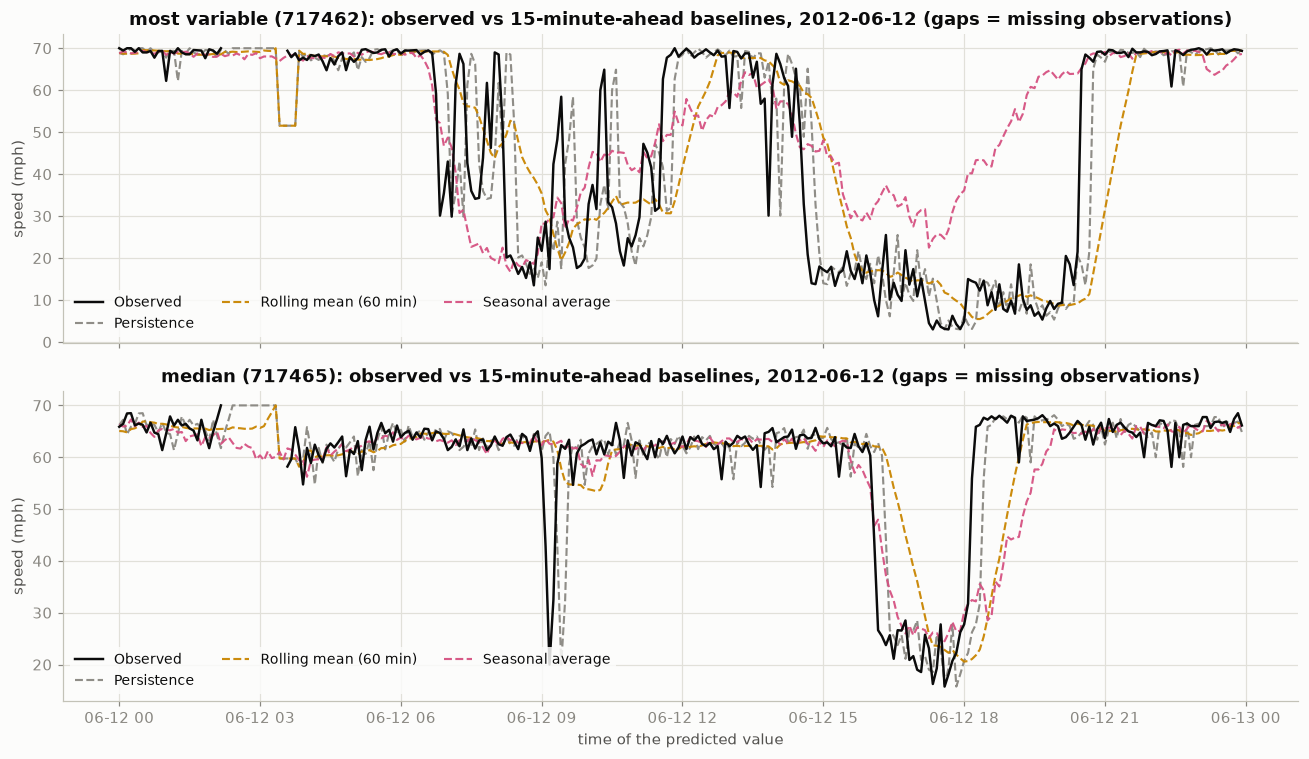

In [7]:
rep = ev.select_representative_sensors(ctx.speed, ctx.mask, ctx.splits.train, ctx.sensor_ids)
rep_labels = {k: f"{k} ({ctx.sensor_ids[v]})" for k, v in rep.items()}
print(rep_labels)

# Actual vs predicted: one weekday of the test period, horizon 15 minutes, 'most variable' sensor and 'median' sensor
j = config.HORIZONS.index(3)
day = pd.Timestamp("2012-06-12")                                   # a Tuesday inside the test period
origins = ctx.origins["test"]; tgt_time = ctx.timestamps[origins + 3]
sel = np.flatnonzero((tgt_time >= day) & (tgt_time < day + pd.Timedelta(days=1)))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, key in zip(axes, ("most_variable", "median")):
    n = rep[key]
    actual = np.where(y_t[sel, j, n] * 0 == 0, y_t[sel, j, n], np.nan)          # NaN stays NaN -> line gap
    viz.plot_actual_vs_predicted(ax, tgt_time[sel], actual, {m: forecasts["test"][m][sel, j, n] for m in BASELINES},
                                 f"{rep_labels[key].replace('_', ' ')}: observed vs 15-minute-ahead baselines, {day.date()} (gaps = missing observations)")
axes[-1].set_xlabel("time of the predicted value")
fig.tight_layout(); viz.save_figure(fig, "04_baselines_actual_vs_predicted"); plt.show()

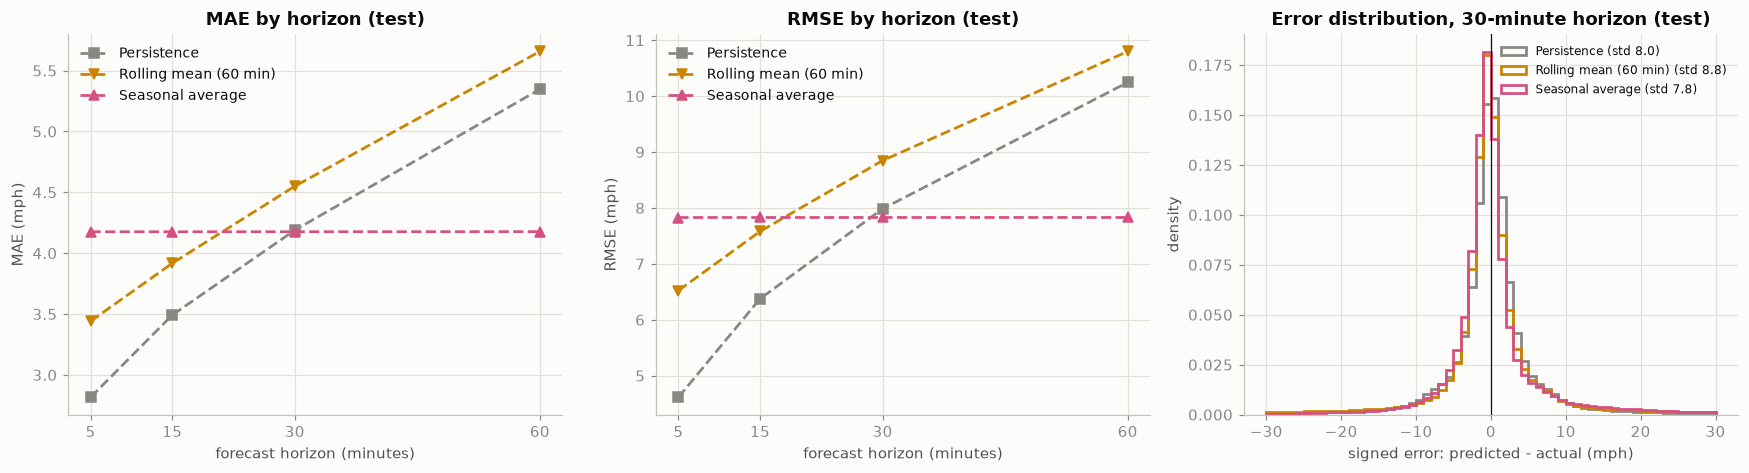

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
viz.plot_metric_vs_horizon(axes[0], table_t, "MAE", BASELINES, title="MAE by horizon (test)")
viz.plot_metric_vs_horizon(axes[1], table_t, "RMSE", BASELINES, title="RMSE by horizon (test)")
# error distribution at 30 minutes (signed error = predicted - actual)
jh = config.HORIZONS.index(6); bins = np.linspace(-30, 30, 61)
for m in BASELINES:
    err = (forecasts["test"][m][:, jh] - y_t[:, jh])[valid_t[:, jh]]
    axes[2].hist(err, bins=bins, histtype="step", lw=1.8, color=viz.style(m)["color"], label=f"{viz.style(m)['label']} (std {err.std():.1f})", density=True)
axes[2].axvline(0, color=viz.INK, lw=0.8); axes[2].set_xlabel("signed error: predicted - actual (mph)"); axes[2].set_ylabel("density")
axes[2].set_title("Error distribution, 30-minute horizon (test)"); axes[2].legend(fontsize=8)
fig.tight_layout(); viz.save_figure(fig, "04_baselines_horizon_and_errors"); plt.show()

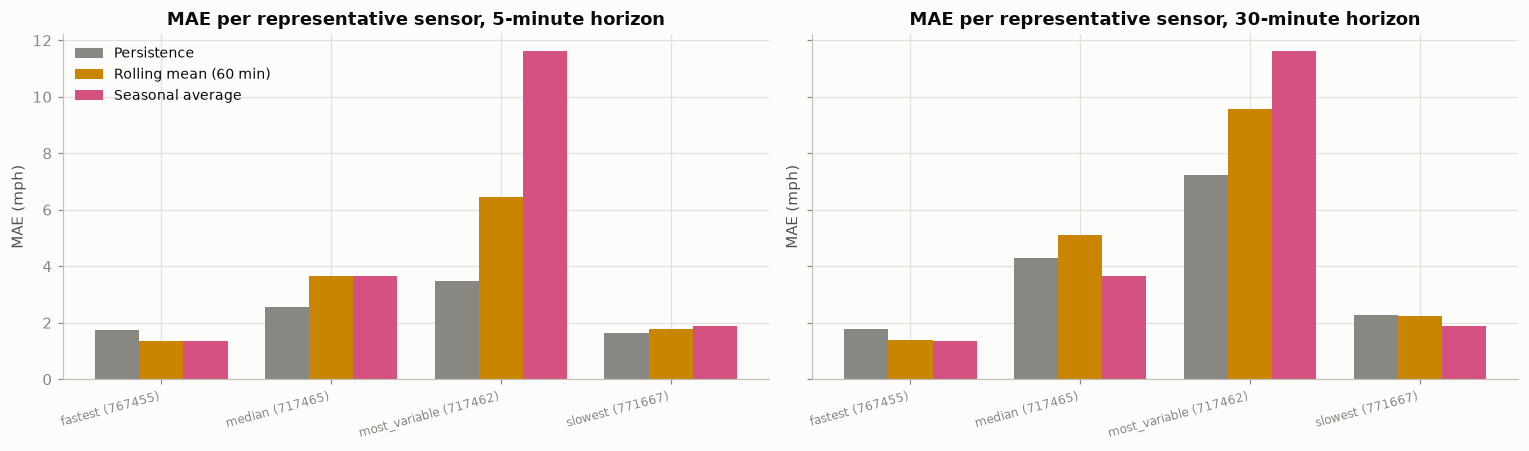

In [9]:
rows = []
for key, n in rep.items():
    for m in BASELINES:
        for hh in (1, 6):
            jj = config.HORIZONS.index(hh)
            met = compute_metrics(forecasts["test"][m][:, jj, n], y_t[:, jj, n], valid_t[:, jj, n])
            rows.append({"sensor": rep_labels[key], "model": viz.style(m)["label"], "horizon_min": hh * 5, "MAE": met["MAE"]})
per_sensor = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, hmin in zip(axes, (5, 30)):
    sub = per_sensor[per_sensor.horizon_min == hmin].pivot(index="sensor", columns="model", values="MAE")
    x = np.arange(len(sub)); w = 0.26
    for k, m in enumerate(BASELINES):
        ax.bar(x + (k - 1) * w, sub[viz.style(m)["label"]], width=w, color=viz.style(m)["color"], label=viz.style(m)["label"])
    ax.set_xticks(x, sub.index, rotation=15, ha="right", fontsize=8); ax.set_title(f"MAE per representative sensor, {hmin}-minute horizon"); ax.set_ylabel("MAE (mph)")
axes[0].legend(); fig.tight_layout(); viz.save_figure(fig, "04_baselines_per_sensor"); plt.show()

## 5 · Interpretation

The claims below are **checked in code** against the test-period metric table (a warning is printed if one does not hold in your run), so the text cannot silently drift from the executed results.

In [10]:
t = table_t.pivot(index="horizon_min", columns="model", values="MAE")
claims = {
    "persistence error grows with the horizon": bool(t["persistence"].is_monotonic_increasing),
    "persistence is the best baseline at the shortest horizon (5 min)": bool(t.loc[5].idxmin() == "persistence"),
    "seasonal-average error is (almost) independent of the horizon": bool(t["seasonal_avg"].max() - t["seasonal_avg"].min() < 0.05),
    "persistence beats the seasonal average at 5 and 15 min": bool((t.loc[[5, 15], "persistence"] < t.loc[[5, 15], "seasonal_avg"]).all()),
    "the seasonal average is within 0.1 mph of persistence at 30 min (a near tie)": bool(abs(t.loc[30, "seasonal_avg"] - t.loc[30, "persistence"]) < 0.1),
    "the seasonal average beats persistence at 60 min": bool(t.loc[60, "seasonal_avg"] < t.loc[60, "persistence"]),
    "the 60-minute rolling mean is worse than persistence at every horizon": bool((t["rolling_mean"] > t["persistence"]).all()),
}
display(ev.report_claims(claims))
print("MAE (mph):"); display(t.round(2))

,claim,holds in this run
0,persistence error grows with the horizon,True
1,persistence is the best baseline at the shorte...,True
2,seasonal-average error is (almost) independent...,True
3,persistence beats the seasonal average at 5 an...,True
4,the seasonal average is within 0.1 mph of pers...,True
5,the seasonal average beats persistence at 60 min,True
6,the 60-minute rolling mean is worse than persi...,True


MAE (mph):


model,persistence,rolling_mean,seasonal_avg
horizon_min,,,
5,2.82,3.44,4.18
15,3.49,3.92,4.18
30,4.19,4.55,4.18
60,5.35,5.66,4.18


**What the baselines show.**

* **Persistence** is very accurate five to fifteen minutes ahead (traffic rarely changes much within minutes) and degrades steadily with the horizon, because it can never anticipate a change.
* The **seasonal average** has the same error at every horizon (its forecast for a given clock time does not depend on when it was made). It roughly ties persistence at 30 minutes and is clearly better at 60 minutes: at longer horizons, knowing the usual pattern is worth more than knowing the current value. Its weakness is any deviation from the usual rhythm.
* The **rolling mean** is worse than persistence at every horizon here: averaging the last hour mostly adds lag.
* **None of them uses the road network.** A model that combines the recent state, the daily rhythm *and* neighbouring sensors has room to beat all three; whether it actually does is the subject of notebooks 05-07.
* The errors are heavy-tailed (the histogram has narrow peaks and long tails): most forecasts are close, a few large misses come from abrupt congestion onset and recovery, which these baselines cannot anticipate.

*Note on the test period:* about 12% of its cells are missing (vs ~7% in training), and missing targets are excluded here exactly as for every other model.